In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
import os
from tqdm import tqdm

In [2]:
rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])

In [3]:
rebecca_data_raman.shape, rebecca_data_ir.shape

((388, 1577), (349, 539))

In [4]:
np.unique(rebecca_data_raman['polymer'])

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

In [5]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca.csv')
Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_specy.csv')
#notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix_std['polymer_raman'], notes_mix_std['polymer_ir'], notes_mix_std['polymer_overall'])]
#Raman_spectra_mix_std = Raman_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)


In [6]:
notes_mix_std_rest.groupby('polymer_overall').count()

,comments,id,polymer_raman,polymer_ir
polymer_overall,,,,
LOW SIGNAL,1,107,107,107
MIXTURE,44,44,44,44
UNSORTED,53,54,54,54


In [7]:
notes_mix_std.groupby('polymer_overall').count()

,comments,id,polymer_raman,polymer_ir
polymer_overall,,,,
NH2SO4,3,45,45,45
NaNO3,2,13,13,13
PE,3,38,38,38
PP,0,4,4,4
PSL,5,13,13,13
sucrose,21,111,111,111


In [8]:
notes_mix_std_rest.groupby('polymer_raman').count()

,comments,id,polymer_overall,polymer_ir
polymer_raman,,,,
LOW SIGNAL,2,108,108,108
MIXTURE,43,43,43,43
NH2SO4,1,1,1,1
PE,2,2,2,2
PSL,5,5,5,5
UNSORTED,32,33,33,33
sucrose,13,13,13,13


In [9]:
notes_mix_std_rest.groupby('polymer_ir').count()

,comments,id,polymer_overall,polymer_raman
polymer_ir,,,,
LOW SIGNAL,22,128,128,128
MIXTURE,34,34,34,34
NH2SO4,6,6,6,6
PE,2,2,2,2
PP,1,1,1,1
PSL,1,1,1,1
UNSORTED,30,31,31,31
sucrose,2,2,2,2


In [10]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix = (IR_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix = IR_spectra_mix.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca.csv')
Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
#notes_mix_rest = np.array(Raman_spectra_mix['comments'])
notes_mix = Raman_spectra_mix.iloc[:,-5:]

notes_mix = (notes_mix.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix.loc[notes_mix['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix.loc[notes_mix['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix.loc[notes_mix['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_rest[[x is np.nan for x in notes_mix_rest]] = ''
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])
Raman_spectra_mix = (Raman_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.sort_values('id').reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
notes_mix_rest = notes_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix['polymer_raman'], notes_mix['polymer_ir'], notes_mix['polymer_overall'])]
#Raman_spectra_mix = Raman_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)


In [11]:
IR_spectra_mix_rest.query('id == 136 or id == 217')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
125,-0.458293,-0.381986,-0.291597,-0.071482,0.102961,0.042253,-0.242010,-0.278758,-0.181451,-0.101000,...,-0.754732,-0.923426,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,136,no_background
128,-0.596220,-0.590548,-0.590095,-0.600481,-0.602661,-0.594409,-0.589836,-0.580672,-0.558146,-0.550383,...,1.858261,1.505509,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,217,no_background


In [12]:
def process_data(rebecca_data_ir, rebecca_data_raman, IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 
    
    wn_rb = np.array(rebecca_data_ir.columns[:-4])
    idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                           np.logical_and(wn_rb > 2720, wn_rb < 2950)
                          ) ) + [False]*4
    
    wn_rb_r = np.array(rebecca_data_raman.columns[:-4])
    idx_rb_r = list(np.logical_and(wn_rb_r > range_r[0], wn_rb_r < range_r[1])) + [False]*4


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4
    
    x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
    x_train_ir = (x_train_ir - x_train_ir.mean(1)[:, None]) / x_train_ir.std(1)[:, None]
    
    y_train_ir = rebecca_data_ir.iloc[:,-2]

    x_train_raman = rebecca_data_raman.iloc[:,idx_rb_r].to_numpy()
    x_train_raman = (x_train_raman - x_train_raman.mean(1)[:, None]) / x_train_raman.std(1)[:, None]
    
    y_train_raman = rebecca_data_raman.iloc[:,-2]

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]
    y_test = IR_spectra.iloc[:,-3]
    
    idx_test = np.sum(np.isnan(x_raman), axis=1) == 0
    ids_test = IR_spectra.loc[idx_test,'id']
    
    x_ir = x_ir[idx_test,:]
    x_raman = x_raman[idx_test,:]
    
    y_raman = y_test[idx_test]
    y_ir = y_test[idx_test]
    
    #y_test[y_test == 'LDPE'] = 'PE'
    
    poly_list = list(np.unique(np.concatenate([y_train_ir, y_train_raman, y_ir]))) 
    label_table = pd.DataFrame({'label':np.arange(len(poly_list)), 'polymer':poly_list})
    
    label_train_Raman = np.array(pd.DataFrame(y_train_raman).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    label_train_IR = np.array(pd.DataFrame(y_train_ir).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    
    label_ir = np.array(pd.DataFrame(y_ir).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    label_raman = np.array(pd.DataFrame(y_raman).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    return x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table, ids_test


In [13]:
def process_data_2(IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]

    y_test = IR_spectra.iloc[:,-3]
    #y_test[y_test == 'LDPE'] = 'PE'
    
    return x_ir, x_raman, y_test

In [14]:
def experiment(score_list, label_ir, alphas, N_sim, quant_prop=.2, cal_prop=.8, seed_init=0):
    df_res_lis = []
    df_res_sd_lis = []
    df_res_all_lis = []
    df_res_cov_all_lis = []
    df_res_all_mean_lis = []
    df_res_cov_all_mean_lis = []
    df_res_cov_lis = []
    df_res_cov_sd_lis = []

    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_all = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        K = 2
        U_list = gen_u(K, seed=0)
        seed = seed_init
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=quant_prop, seed=seed)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=cal_prop, seed=seed)
                

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]
            #n = quant_labels.shape[0]

            prediction_sets, empirical_coverage, U_quant_env = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list, #quant_smx_list,
                                                             cal_labels, #quant_labels,
                                                             val_smx_list, #rest_smx_list, 
                                                             alpha, 
                                                             val_labels, #rest_labels,
                                                             U=U_list[0])

            
                


            set_size['mvcp'].append(
                    prediction_sets.sum(1).mean()
                )
            set_size_all['mvcp'].append(
                    prediction_sets.sum(1)
                )
            cov_all['mvcp'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels]
                )
            zero_sets['mvcp'].append(
                    np.mean(prediction_sets.sum(1) == 0)
                )
            cov['mvcp'].append(
                    empirical_coverage
                )

            set_size_by_label_hqi['mvcp'].append(
                    pd.DataFrame({'label':val_labels, #rest_labels,
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

            s_u = rest_smx_list[0]

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            #cal_smx, val_smx, cal_labels, val_labels = quant_smx_list[0], rest_smx_list[0], quant_labels, rest_labels
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['view_IR'].append(prediction_sets.sum(1).mean())

            set_size_all['view_IR'].append(
                    prediction_sets.sum(1)
                )
            cov_all['view_IR'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels]
                )

            zero_sets['view_IR'].append(np.mean(prediction_sets.sum(1) == 0))
            cov['view_IR'].append(empirical_coverage)

            set_size_by_label_hqi['view_IR'].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

            s_u = rest_smx_list[1]

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
            #cal_smx, val_smx, cal_labels, val_labels = quant_smx_list[1], rest_smx_list[1], quant_labels, rest_labels
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['view_Raman'].append(prediction_sets.sum(1).mean())

            set_size_all['view_Raman'].append(
                    prediction_sets.sum(1)
                )
            cov_all['view_Raman'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels]
                )

            zero_sets['view_Raman'].append(np.mean(prediction_sets.sum(1) == 0))
            cov['view_Raman'].append(empirical_coverage)

        df_res_all_lis.append(set_size_all)
        df_res_cov_all_lis.append(cov_all)
        
        df_res_all_mean_lis.append(set_size)
        df_res_cov_all_mean_lis.append(cov)
        
        df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_sd_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).std()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_sd_lis.append(df_res)

    return df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_mean_lis, df_res_cov_all_mean_lis, df_res_all_lis, df_res_cov_all_lis


# Mix-Std

In [204]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table, ids_test = process_data(rebecca_data_ir, 
                                                                                                     rebecca_data_raman, 
                                                                                                     pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True),
                                                                                                     pd.concat([Raman_spectra_mix_std, Raman_spectra_mix], axis=0).reset_index(drop=True))

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(
                                                    pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True),
                                                    pd.concat([Raman_spectra_mix_std_rest, Raman_spectra_mix_rest], axis=0).reset_index(drop=True)
                                                   )



In [205]:
[x.shape for x in [x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table]]


[(349, 525),
 (388, 1475),
 (349,),
 (388,),
 (530, 525),
 (530, 1475),
 (530,),
 (530,),
 (6, 2)]

In [206]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

In [207]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [208]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman)

(0.8, 0.8056603773584906)

In [20]:
alphas = np.arange(0,.2,.01)
N_sim = 50


In [21]:

(df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_mean_lis, df_res_cov_all_mean_lis, df_res_all_lis, df_res_cov_all_lis)  = experiment(score_list, 
                                                                                          label_ir, 
                                                                                          alphas,
                                                                                          N_sim, 
                                                                                          quant_prop=.2, 
                                                                                          cal_prop=0.8, 
                                                                                          seed_init=0)



100%|███████████████████████████████████████████| 20/20 [01:18<00:00,  3.94s/it]


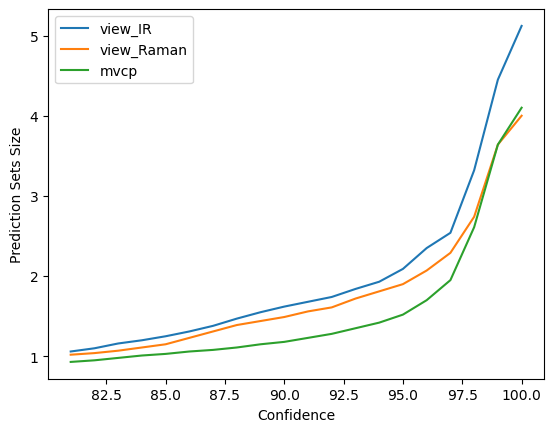

In [22]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [24]:
df_res_all.to_csv('results/data_fig_2.csv')

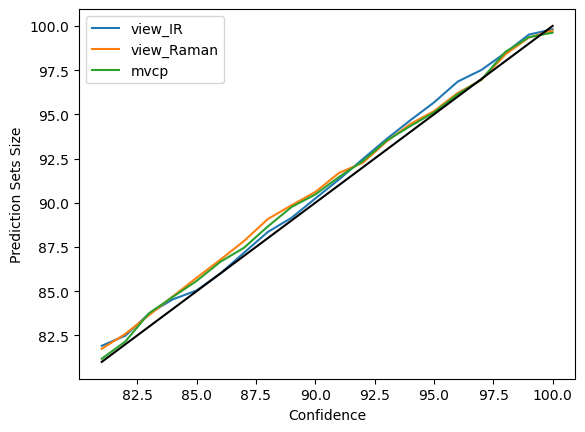

In [25]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
#np.round(df_res_all, 2)
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.plot(df_res_all['confidence'],df_res_all['confidence'], color='black')
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [26]:
(df_res_lis, 
 df_res_sd_lis, 
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis,
 df_res_all_lis, 
 df_res_cov_all_lis)  = experiment(score_list, 
                                                                                          label_ir, 
                                                                                          [0.05],
                                                                                          N_sim, 
                                                                                          quant_prop=.2, 
                                                                                          cal_prop=0.8, 
                                                                                          seed_init=0)

100%|█████████████████████████████████████████████| 1/1 [00:04<00:00,  4.78s/it]


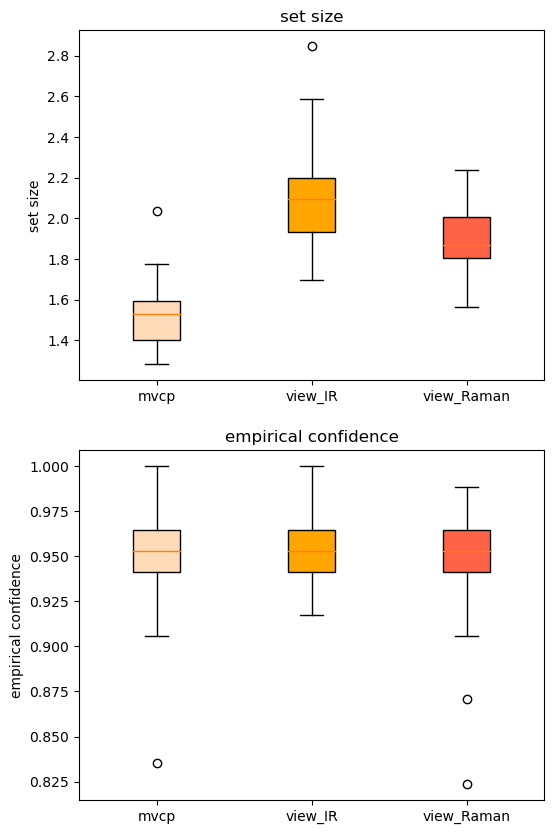

In [31]:
fig, ax = plt.subplots(nrows=2, figsize=(6, 10))
title = ['none', 'low', 'medium', 'high']
set_size = [np.array(df_res_all_mean_lis[0][x]) for x in df_res_all_mean_lis[0]]
cov = [np.array(df_res_cov_all_mean_lis[0][x]) for x in df_res_cov_all_mean_lis[0]]


labels = list(df_res_all_mean_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato']

ax[0].set_ylabel('set size')
ax[0].set_title('set size')

bplot = ax[0].boxplot(set_size,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    
    
labels = list(df_res_cov_all_mean_lis[0].keys())   
ax[1].set_ylabel('empirical confidence')
ax[1].set_title('empirical confidence')

bplot = ax[1].boxplot(cov,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()

In [32]:
df_res_all_mean_lis[0]

defaultdict(list,
            {'mvcp': [1.6470588235294117,
              1.776470588235294,
              1.5411764705882354,
              1.3176470588235294,
              1.4470588235294117,
              1.576470588235294,
              1.7294117647058824,
              1.3529411764705883,
              1.5411764705882354,
              1.3294117647058823,
              1.7176470588235293,
              1.5529411764705883,
              1.3294117647058823,
              1.576470588235294,
              1.4470588235294117,
              1.611764705882353,
              1.4705882352941178,
              1.3294117647058823,
              1.3529411764705883,
              1.4470588235294117,
              1.4,
              1.3294117647058823,
              1.5529411764705883,
              1.576470588235294,
              1.3529411764705883,
              2.0352941176470587,
              1.7058823529411764,
              1.5294117647058822,
              1.5176470588235293,
        

In [595]:
pd.concat([pd.DataFrame({'set_size_'+x:set_size[i] for i, x in enumerate(df_res_all_mean_lis[0])}),
              pd.DataFrame({'cov_'+x:cov[i] for i, x in enumerate(df_res_cov_all_mean_lis[0])})], axis=1).to_csv('results/data_fig_2c.csv')

In [562]:
table_fig2d = pd.DataFrame({'set_size':np.concatenate(df_res_all_lis[0]['mvcp']),
                            'cov':np.concatenate(df_res_cov_all_lis[0]['mvcp'])})#.groupby('set_size').sum()
table_fig2d = pd.concat([table_fig2d.groupby('set_size').count(),
           table_fig2d.groupby('set_size').mean(),
           1-table_fig2d.groupby('set_size').mean()], axis=1)
table_fig2d.columns = ['number of spectra', 'correct label in prediction set', 'correct label not in prediction set']
table_fig2d

,number of spectra,correct label in prediction set,correct label not in prediction set
set_size,,,
0,59,0.000000,1.000000
1,3170,0.972555,0.027445
2,484,0.917355,0.082645
3,176,0.897727,0.102273
4,122,0.967213,0.032787
5,134,1.000000,0.000000
6,105,1.000000,0.000000


In [596]:
table_fig2d_aux.to_csv('results/data_fig_2d.csv')

In [592]:
table_fig2d_list = []

table_fig2d_aux = pd.DataFrame(np.zeros((7,3)))
table_fig2d_aux.columns = ['number of spectra', 'correct label in prediction set', 'correct label not in prediction set']

set_size_list_df = pd.DataFrame({'set_size':np.arange(7)})
set_size_list_df

for df_ss, df_cov in zip(df_res_all_lis[0]['mvcp'], df_res_cov_all_lis[0]['mvcp']):
    table_fig2d = pd.DataFrame({'set_size':df_ss,
                                'cov':df_cov})
    
    table_fig2d = pd.concat([table_fig2d.groupby('set_size').count(),
                             table_fig2d.groupby('set_size').mean(),
                             1-table_fig2d.groupby('set_size').mean()], axis=1)
    
    table_fig2d.columns = ['number of spectra', 'correct label in prediction set', 'correct label not in prediction set']
    table_fig2d = table_fig2d.reset_index()
    table_fig2d = pd.merge(set_size_list_df, table_fig2d, on='set_size', how='left')
    table_fig2d[np.isnan(table_fig2d)] = 0
    table_fig2d_aux = table_fig2d_aux + table_fig2d.iloc[:,1:]
    table_fig2d_list.append(table_fig2d)

table_fig2d_aux = table_fig2d_aux / np.array([np.array([50]*7),
          np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list])),
          np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list]))]).T

In [593]:
table_fig2d_aux

,number of spectra,correct label in prediction set,correct label not in prediction set
0,1.18,0.000000,1.000000
1,63.40,0.972580,0.027420
2,9.68,0.907809,0.092191
3,3.52,0.892429,0.107571
4,2.44,0.963830,0.036170
5,2.68,1.000000,0.000000
6,2.10,1.000000,0.000000


In [584]:
sum(table_fig2d_aux['number of spectra']*table_fig2d_aux.index)/sum(table_fig2d_aux['number of spectra'])

1.5394742976060476

In [431]:
sum(table_fig2d['number of spectra']*table_fig2d.index)/sum(table_fig2d['number of spectra'])

1.5380999505195447

In [566]:
table_fig2d_list[0]

,set_size,number of spectra,correct label in prediction set,correct label not in prediction set
0,0,2,0.000000,1.000000
1,1,58,0.965517,0.034483
2,2,10,1.000000,0.000000
3,3,7,0.857143,0.142857
4,4,3,1.000000,0.000000
5,5,1,1.000000,0.000000
6,6,4,1.000000,0.000000


In [380]:
#(score_list, label_ir, alphas, N_sim, seed_init) = (score_list, label_ir, alphas, N_sim, seed_init)
seed_init = 0
alphas = np.array([.001])
N_sim = 1

df_res_lis = []
df_res_sd_lis = []
df_res_all_lis = []
df_res_cov_all_lis = []
df_res_cov_lis = []
df_res_cov_sd_lis = []
    
for alpha in tqdm(alphas):
    set_size = defaultdict(list)
    set_size_all = defaultdict(list)
    zero_sets = defaultdict(list)
    cov = defaultdict(list)
    cov_cal = defaultdict(list)
    set_size_by_label_hqi = defaultdict(list)
    K = 2
    U_list = gen_u(K, seed=0)
    seed = seed_init
    for l in range(N_sim):
        seed = seed + l
        quant_smx_list = []
        rest_smx_list = []
        cal_smx_list = []
        val_smx_list = []
        
        for i in range(K):

            quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.6, seed=seed)
            
            quant_smx_list.append(quant_smx)
            rest_smx_list.append(rest_smx)
            cal_smx_list.append(cal_smx)
            val_smx_list.append(val_smx)

        n = cal_labels.shape[0]

        prediction_sets, empirical_coverage, U_quant_env = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list, 
                                                             cal_labels, 
                                                             val_smx_list, 
                                                             alpha, 
                                                             val_labels, 
                                                             U=U_list[0])

            
                


        set_size['mvcp'].append(
                    prediction_sets.sum(1).mean()
                )
        set_size_all['mvcp'].append(
                    prediction_sets.sum(1)
                )
        zero_sets['mvcp'].append(
                    np.mean(prediction_sets.sum(1) == 0)
                )
        cov['mvcp'].append(
                    empirical_coverage
                )

        set_size_by_label_hqi['mvcp'].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

        s_u = rest_smx_list[0]

        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.6, seed=seed)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
        set_size['view_IR'].append(prediction_sets.sum(1).mean())

        set_size_all['view_IR'].append(
                    prediction_sets.sum(1)
                )

        zero_sets['view_IR'].append(np.mean(prediction_sets.sum(1) == 0))
        cov['view_IR'].append(empirical_coverage)

        set_size_by_label_hqi['view_IR'].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

        s_u = rest_smx_list[1]

        cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.6, seed=seed)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)            
        set_size['view_Raman'].append(prediction_sets.sum(1).mean())

        set_size_all['view_Raman'].append(
                    prediction_sets.sum(1)
                )

        zero_sets['view_Raman'].append(np.mean(prediction_sets.sum(1) == 0))
        cov['view_Raman'].append(empirical_coverage)

    
    df_res_all_lis.append(set_size)
    df_res_cov_all_lis.append(cov)
        
    df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
    df_res['M'] = 1
    df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)

    df_res_lis.append(df_res)

    df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
    df_res['M'] = 1
    df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)

    df_res_sd_lis.append(df_res)

    df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
    df_res['M'] = 1
    df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)

    df_res_cov_lis.append(df_res)

    df_res = pd.DataFrame(pd.DataFrame(cov).std()).reset_index()
    df_res['M'] = 1
    df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)

    df_res_cov_sd_lis.append(df_res)


100%|█████████████████████████████████████████████| 1/1 [00:00<00:00, 19.79it/s]


array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [384]:
empirical_coverage

1.0

In [381]:
pd.DataFrame({'label':quant_labels, 'n':1}).groupby('label').sum() / (pd.DataFrame({'label':quant_labels, 'n':1}).groupby('label').sum().sum())

,n
label,
0,0.056604
1,0.037736
2,0.386792
3,0.160377
4,0.113208
5,0.245283


In [377]:
pd.DataFrame({'label':rest_labels, 'n':1}).groupby('label').sum() / (pd.DataFrame({'label':rest_labels, 'n':1}).groupby('label').sum().sum())

,n
label,
0,0.091981
1,0.021226
2,0.287736
3,0.195755
4,0.202830
5,0.200472


In [378]:
pd.DataFrame({'label':cal_labels, 'n':1}).groupby('label').sum() / (pd.DataFrame({'label':cal_labels, 'n':1}).groupby('label').sum().sum())


,n
label,
0,0.094488
1,0.019685
2,0.267717
3,0.224409
4,0.173228
5,0.220472


In [199]:
pd.DataFrame({'label':val_labels, 'n':1}).groupby('label').sum() / (pd.DataFrame({'label':val_labels, 'n':1}).groupby('label').sum().sum())


,n
label,
0,0.250000
1,0.055556
2,0.138889
4,0.055556
5,0.500000


In [187]:
np.quantile(cal_smx[np.arange(cal_smx.shape[0]), cal_labels], .9999)

0.25549354990501044

In [188]:
qhat

0.2570494415532891

In [72]:
smx_all_Raman.shape

(224, 6)

In [52]:
df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
df_res
#df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = 1
#del df_res['index']
df_res = df_res.pivot(index='M',columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res = df_res.reset_index(drop=True)

df_res

index,view_IR,view_Raman,mvcp
0,3.663889,3.831481,3.45


(array([32., 66., 80., 28., 12.,  4.,  0.,  1.,  0.,  1.]),
 array([0.0099437 , 0.03465428, 0.05936485, 0.08407543, 0.108786  ,
        0.13349657, 0.15820715, 0.18291772, 0.20762829, 0.23233887,
        0.25704944]),
 <BarContainer object of 10 artists>)

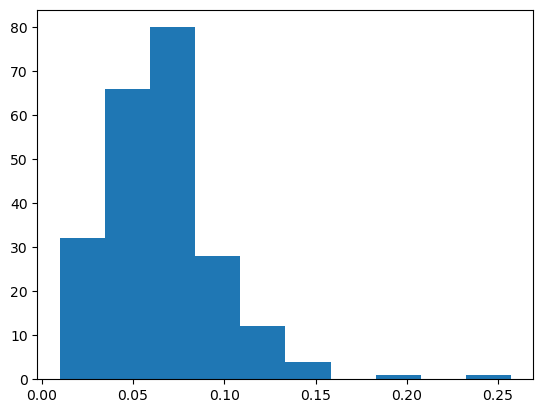

In [140]:
plt.hist(smx_all_Raman[np.arange(label_raman.shape[0]),label_raman])

(array([282., 310., 229., 129.,  88.,  43.,  27.,   7.,   3.,   2.]),
 array([0.04581554, 0.12679092, 0.20776631, 0.2887417 , 0.36971709,
        0.45069248, 0.53166787, 0.61264326, 0.69361865, 0.77459404,
        0.85556943]),
 <BarContainer object of 10 artists>)

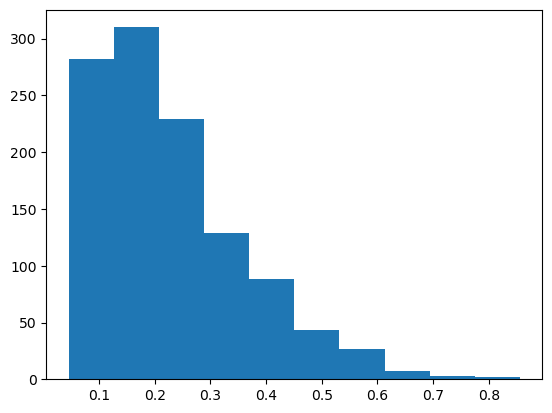

(array([1.88177635, 3.46175839, 3.2487271 , 1.88177635, 1.17167207,
        0.71010428, 0.30179432, 0.14202086, 0.03550521, 0.03550521]),
 array([0.0786073 , 0.15630351, 0.23399972, 0.31169594, 0.38939215,
        0.46708836, 0.54478458, 0.62248079, 0.700177  , 0.77787322,
        0.85556943]),
 <BarContainer object of 10 artists>)

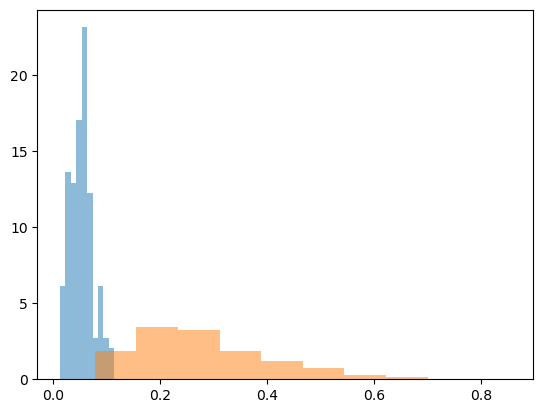

In [175]:
plt.hist(smx_all_IR[np.arange(label_ir.shape[0]),label_raman], alpha=.5, density=True)
plt.hist(smx_all_IR[~np.array([[x == i for i in range(6)] for x in label_raman])], alpha=.5, density=True)

(array([0.27657786, 3.61678745, 2.89342996, 2.89342996, 1.82966895,
        1.42543976, 0.85100881, 0.87228403, 0.46805485, 0.29785308]),
 array([0.03519332, 0.1000251 , 0.16485688, 0.22968866, 0.29452043,
        0.35935221, 0.42418399, 0.48901577, 0.55384754, 0.61867932,
        0.6835111 ]),
 <BarContainer object of 10 artists>)

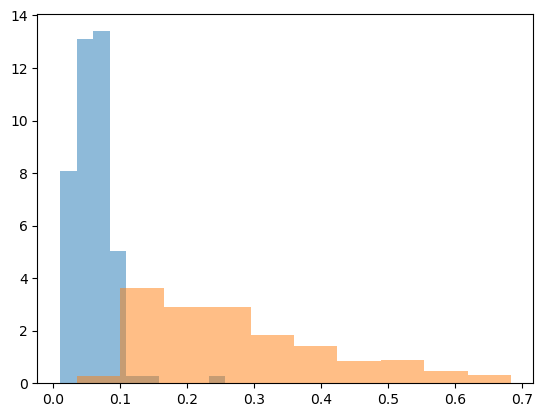

In [176]:
plt.hist(smx_all_Raman[np.arange(label_ir.shape[0]),label_raman], alpha=.5, density=True)
plt.hist(smx_all_Raman[~np.array([[x == i for i in range(6)] for x in label_raman])], alpha=.5, density=True)

In [43]:
def envelop(score_list, label_ir, score_example, alphas, N_sim=1, quant_prop=.2, cal_prop=.8, seed_init=0):
    env_list = defaultdict(list)
    ps_list = defaultdict(list)
    ps_ir_list = defaultdict(list)
    ps_raman_list = defaultdict(list)
    q_ir_list = defaultdict(list)
    q_raman_list = defaultdict(list)
        
    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        K = 2
        U_list = gen_u(K, n_th=4000, seed=0)
        seed = seed_init
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=quant_prop, seed=seed)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=cal_prop, seed=seed)
                

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]
            #n = quant_labels.shape[0]

            prediction_sets, U_quant_env = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list, #quant_smx_list,
                                                             cal_labels, #quant_labels,
                                                             score_example,#val_smx_list, #rest_smx_list, 
                                                             alpha, 
                                                             val_labels=None, #rest_labels,
                                                             U=U_list[0])

            
            s_u = rest_smx_list[0]

            cal_ir_smx, val_ir_smx, cal_ir_labels, val_ir_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            n = cal_ir_smx.shape[0]
            prediction_sets_ir, qhat_ir = conform_prediction(cal_ir_smx, score_example[0], cal_ir_labels, n, alpha, val_labels=None, cond=0)

            s_u = rest_smx_list[1]

            cal_raman_smx, val_raman_smx, cal_raman_labels, val_raman_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            n = cal_raman_smx.shape[0]
            prediction_sets_raman, qhat_raman = conform_prediction(cal_raman_smx, score_example[1], cal_raman_labels, n, alpha, val_labels=None, cond=0)            

            
            ps_ir_list[int(100*alpha)].append(list(label_table.loc[prediction_sets_ir[0], 'polymer']))            
            ps_raman_list[int(100*alpha)].append(list(label_table.loc[prediction_sets_raman[0], 'polymer']))            
            ps_list[int(100*alpha)].append(list(label_table.loc[prediction_sets[0], 'polymer']))
            

            beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels, U=U_list[0])

            n = cal_smx_list[0].shape[0]
            t = np.max([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0)
            q_level = np.clip(np.ceil((n+1)*(1-alpha))/n, 0, 1)
            t_quant = np.quantile(t, q_level, method='higher')
            cal_smx_arr = np.array([cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                                    cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]])
            
            plt.scatter(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                        cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels], 
                        label='calibration set')

        
            idx_quant_reg = np.argsort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_x = t_quant*np.sort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_y = t_quant*(cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]/t)[idx_quant_reg]
            
            q_ir_list[int(100*alpha)].append(qhat_ir)
            q_raman_list[int(100*alpha)].append(qhat_raman)
            env_list[int(100*alpha)].append([quant_reg_x, quant_reg_y])
            
            print("MVCP", ps_list[int(100*alpha)][-1])
            print("IR", ps_ir_list[int(100*alpha)][-1])
            print("Raman", ps_raman_list[int(100*alpha)][-1])
            
            for th in range(U_list[0].shape[0]):
                u = U_list[0][th]
                plt.scatter(u[0]*q_array[th],
                            u[1]*q_array[th],
                            c='yellow',
                            s=1)
            
            plt.scatter(U_quant_env[:,0],
                        U_quant_env[:,1],
                            c='green',
                            s=1)
            
            plt.plot(quant_reg_x,
                     quant_reg_y, 
                     label=str(int(100*(1-alpha)))+' quantile region',
                     c='orange',
                     linewidth=3.0
                 )
            
            _ = plt.vlines(x= qhat_ir,
                ymin=0,
                ymax=.25,
                colors='r',
                alpha=.5,
                linestyles='solid',
                label='95 IR Quantile')

            _ = plt.hlines(y= qhat_raman,
                            xmin=0,
                            xmax=.7,
                            colors='purple',
                            alpha=.5,
                            linestyles='solid',
                            label='95 Raman Quantile')

            plt.scatter(score_example[0],
                        score_example[1], c='r')
            
            for i in range(6):
                plt.text(score_example[0][0, i], 
                         score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')

            plt.xlabel("IR 1-HQI")
            plt.ylabel("Raman 1-HQI")

            plt.legend()
            plt.show()


    

    return ps_list, ps_ir_list, ps_raman_list, env_list, cal_smx_arr, q_ir_list, q_raman_list


In [215]:
def envelop_aux(score_list, label_ir, score_example, alphas, N_sim=1, quant_prop=.2, cal_prop=.8, seed_init=0):
    env_list = defaultdict(list)
    ps_list = defaultdict(list)
    ps_ir_list = defaultdict(list)
    ps_raman_list = defaultdict(list)
    q_ir_list = defaultdict(list)
    q_raman_list = defaultdict(list)
        
    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        K = 2
        U_list = gen_u(K, n_th=400, seed=0)
        seed = seed_init
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=quant_prop, seed=seed)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=cal_prop, seed=seed)
                

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]
            #n = quant_labels.shape[0]

            prediction_sets, U_quant_env = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list, #quant_smx_list,
                                                             cal_labels, #quant_labels,
                                                             score_example,#val_smx_list, #rest_smx_list, 
                                                             alpha, 
                                                             val_labels=None, #rest_labels,
                                                             U=U_list[0])

            
            
            ps_list[int(100*alpha)].append(list(label_table.loc[prediction_sets[0], 'polymer']))
            

            beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels, U=U_list[0])

            n = cal_smx_list[0].shape[0]
            t = np.max([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0)
            q_level = np.clip(np.ceil((n+1)*(1-alpha))/n, 0, 1)
            t_quant = np.quantile(t, q_level, method='higher')
            cal_smx_arr = np.array([cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                                    cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]])
            
            
            plt.scatter(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                        cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels], 
                        label='calibration set')

        
            idx_quant_reg = np.argsort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_x = t_quant*np.sort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_y = t_quant*(cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]/t)[idx_quant_reg]
            
            env_list[int(100*alpha)].append([quant_reg_x, quant_reg_y])
            
            print("MVCP", ps_list[int(100*alpha)][-1])
            
            for th in range(U_list[0].shape[0]):
                u = U_list[0][th]
                plt.scatter(u[0]*q_array[th],
                            u[1]*q_array[th],
                            c='yellow',
                            s=1)
            
            plt.scatter(U_quant_env[:,0],
                        U_quant_env[:,1],
                            c='green',
                            s=1)
            
            plt.plot(quant_reg_x,
                     quant_reg_y, 
                     label=str(int(100*(1-alpha)))+' quantile region',
                     c='orange',
                     linewidth=3.0
                 )

            plt.scatter(score_example[0],
                        score_example[1], c='r')
            
            for i in range(6):
                plt.text(score_example[0][0, i], 
                         score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')

            plt.xlabel("IR 1-HQI")
            plt.ylabel("Raman 1-HQI")

            plt.legend()
            plt.show()


    

    return ps_list, env_list, cal_smx_arr, quant_smx_list, quant_labels, cal_smx_list, cal_labels, q_array, U_quant_env, U


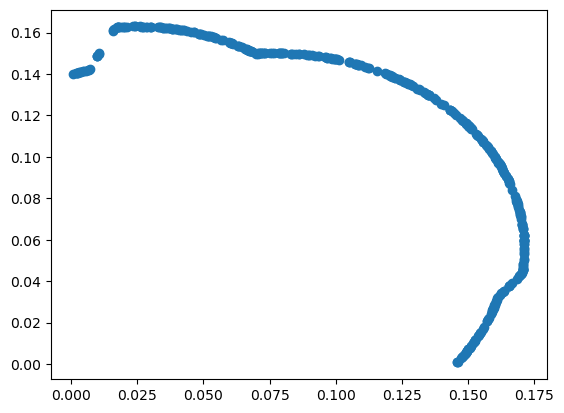

In [299]:
plt.scatter(U_quant_env[:,0],
            U_quant_env[:,1])

In [300]:
beta_, q_array_, U_ = calibrate_beta_mv(0.05, quant_smx_list, quant_labels, U=U)

In [301]:
n_th = 400
q_list = []
cov_list = []
score_list = quant_smx_list
n = quant_labels.shape[0]
for th in range(n_th):#np.linspace(0,np.pi/2,n_th):
    u = U[th,:] #/ np.linalg.norm(U[th,:])
    cal_s_u, _ = project_u_mv(score_list, u)
    cal_scores = cal_s_u[np.arange(n),quant_labels]
    q_level = np.clip(np.ceil((n+1)*(1-beta_))/n, 0, 1)#np.ceil((n+1)*(1-beta))/n
            #q_level = min(q_level, 1)
    qhat = np.quantile(cal_scores, q_level, method='higher')
    cov_list.append(cal_scores <= qhat)
    q_list.append(qhat)

In [302]:
env_quant = np.array([U[i,:]*q_list[i] for i in range(400)])


In [303]:
np.array(env_quant_2)

array([], dtype=float64)

In [304]:
env_quant - np.array(env_quant_2)

ValueError: operands could not be broadcast together with shapes (400,2) (0,) 

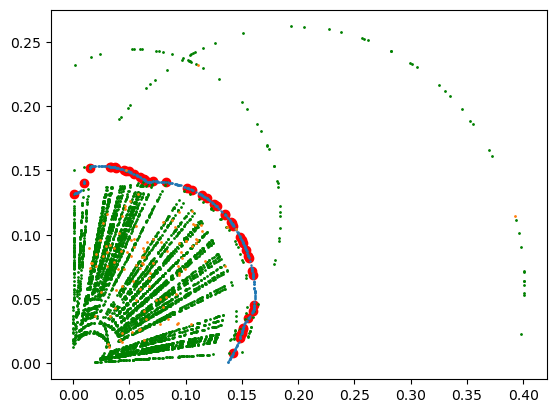

In [305]:
env_quant_2 = []
for th in range(50):
    #th = 0
    u = U[th,:] #/ np.linalg.norm(U[th,:])
    cal_s_u, _ = project_u_mv(score_list, u)
    cal_scores = cal_s_u[np.arange(n),quant_labels]
    cal_scores_vect = np.array([u*s for s in cal_scores])

    plt.scatter(cal_scores_vect[np.where(cal_scores == np.quantile(cal_scores, q_level, method='higher'))[0][0], 0],
                cal_scores_vect[np.where(cal_scores == np.quantile(cal_scores, q_level, method='higher'))[0][0], 1],c='r')
    
    env_quant_2.append([cal_scores_vect[np.where(cal_scores == np.quantile(cal_scores, q_level, method='higher'))[0][0], 0],
                        cal_scores_vect[np.where(cal_scores == np.quantile(cal_scores, q_level, method='higher'))[0][0], 1]])
    plt.scatter(cal_scores_vect[:,0],
                cal_scores_vect[:,1],c='g',s=1)
plt.scatter(env_quant[:,0],
            env_quant[:,1], s=.5)
plt.scatter(quant_smx_list[0][np.arange(quant_labels.shape[0]), quant_labels],
            quant_smx_list[1][np.arange(quant_labels.shape[0]), quant_labels], s=1)


In [230]:
alpha = 0.05
n_th = U.shape[0]
prediction_sets_list = []
n = cal_labels.shape[0]
    #th_s = np.linspace(0,np.pi/2,n_th) 
t = np.max([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0)
q_level = np.clip(np.ceil((n+1)*(1-alpha))/n, 0, 1)#np.ceil((n+1)*(1-alpha))/n
t_quant = np.quantile(t, q_level, method='higher')
t_quant

1.060925208464543

In [236]:

project_u_mv(cal_smx_list, 
             #U[th,:]
             U[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0),:][0,:]
            )[0]


array([[0.29694043, 0.40851009, 0.28909778, 0.22805734, 0.3210599 ,
        0.0769475 ],
       [0.03829866, 0.42099414, 0.46736709, 0.43543616, 0.43752553,
        0.39856967],
       [0.01866213, 0.78493832, 0.78551968, 0.76248436, 0.76946364,
        0.73506053],
       ...,
       [0.19793988, 0.17375734, 0.12003823, 0.15378347, 0.15689129,
        0.14030222],
       [0.23294669, 0.24710038, 0.0859547 , 0.21096622, 0.22337261,
        0.19485645],
       [0.37862697, 0.5077574 , 0.26751396, 0.07156751, 0.36369714,
        0.25341202]])

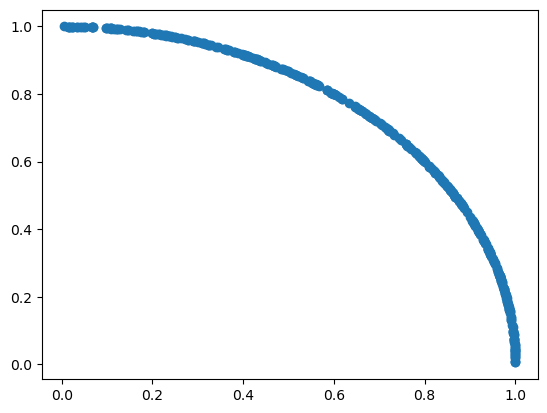

In [264]:
plt.scatter(U[:,0],
            U[:,1])

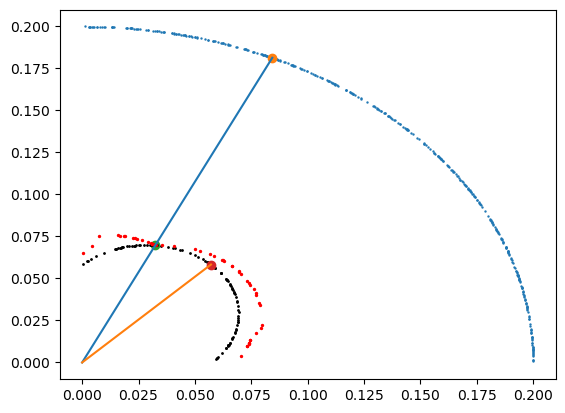

In [333]:
plt.scatter(U[:,0]*.2,
            U[:,1]*.2,s=.5)

plt.scatter(U_t[0,0]*.2, 
            U_t[0,1]*.2)

plt.scatter(U_t[0,0]*(cal_smx_list[0][0][cal_labels[0]]*U_t[0,0] + cal_smx_list[1][0][cal_labels[0]]*U_t[0,1]), 
            U_t[0,1]*(cal_smx_list[0][0][cal_labels[0]]*U_t[0,0] + cal_smx_list[1][0][cal_labels[0]]*U_t[0,1]))

for i in range(100):
    plt.scatter(U[i,0]*(cal_smx_list[0][0][cal_labels[0]]*U[i,0] + cal_smx_list[1][0][cal_labels[0]]*U[i,1]), 
                U[i,1]*(cal_smx_list[0][0][cal_labels[0]]*U[i,0] + cal_smx_list[1][0][cal_labels[0]]*U[i,1]), s=1, c='black')


plt.plot([0,U_t[0,0]*.2], 
            [0,U_t[0,1]*.2])

plt.scatter(cal_smx_list[0][0][cal_labels[0]], 
            cal_smx_list[1][0][cal_labels[0]])

plt.plot([0, cal_smx_list[0][0][cal_labels[0]]], 
          [0,  cal_smx_list[1][0][cal_labels[0]]])

fctor = t[0]
plt.scatter(fctor*np.array(env_quant_2)[:,0],
            fctor*np.array(env_quant_2)[:,1],s=2,c='r')

In [331]:
t

array([0.49407296, 0.25153218, 0.17599634, 0.35554498, 0.38996663,
       0.64745031, 0.49746192, 0.30223049, 0.73855699, 0.47887626,
       0.81307664, 0.49213554, 0.62887667, 0.62871969, 0.4723995 ,
       0.35389913, 0.40780449, 0.69994104, 0.55718766, 0.62635147,
       0.73321003, 0.48929226, 0.68226721, 0.5555523 , 0.84104172,
       1.0096359 , 0.63096828, 0.56809771, 0.5252371 , 0.65055503,
       0.50468169, 0.60316054, 0.72755545, 0.61795909, 0.46527582,
       0.22934594, 0.771934  , 0.76280662, 0.17126971, 0.44917137,
       0.75903718, 0.63525141, 0.52751498, 0.81551248, 0.23435911,
       0.46801672, 0.72082118, 0.3998719 , 0.3431659 , 0.717603  ,
       0.4627565 , 0.19729474, 0.67116707, 0.30071668, 0.63359688,
       0.72142496, 0.65584439, 0.4339485 , 0.72196401, 0.51991906,
       0.39691111, 0.68048027, 0.9286311 , 0.38013755, 0.65515431,
       0.49271206, 0.3074899 , 0.54849402, 0.70971866, 0.47501204,
       0.78480459, 0.75135759, 0.68336337, 1.18613585, 0.80602

In [329]:
U_t = U[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(cal_labels.shape[0]),cal_labels]/q for th, q in enumerate(q_array)], 0),:]
U_t

array([[0.42166723, 0.90675065],
       [0.0481348 , 0.99884085],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.0058794 , 0.99998272],
       [0.99998543, 0.00539881],
       [0.42166723, 0.90675065],
       [0.42166723, 0.90675065],
       [0.0058794 , 0.99998272],
       [0.42166723, 0.90675065],
       [0.0481348 , 0.99884085],
       [0.42166723, 0.90675065],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.42166723, 0.90675065],
       [0.0481348 , 0.99884085],
       [0.0481348 , 0.99884085],
       [0.99998543, 0.00539881],
       [0.42166723, 0.90675065],
       [0.0058794 , 0.99998272],
       [0.0058794 , 0.99998272],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.0481348 , 0.99884085],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.99998543, 0.00539881],
       [0.

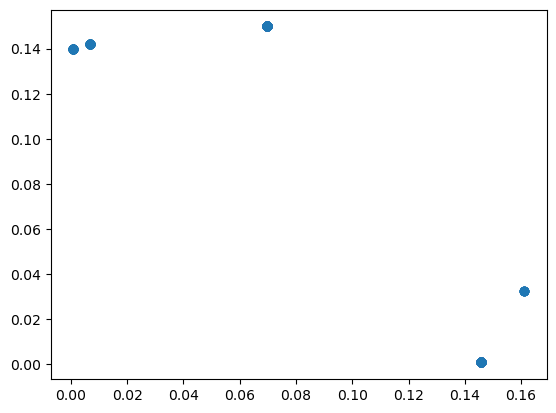

In [261]:

U_t = U[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0),:]
plt.scatter(t_quant*U_t[:,0]*q_array[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0)],
            t_quant*U_t[:,1]*q_array[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0)])


In [231]:
t

array([0.49407296, 0.25153218, 0.17599634, 0.35554498, 0.38996663,
       0.64745031, 0.49746192, 0.30223049, 0.73855699, 0.47887626,
       0.81307664, 0.49213554, 0.62887667, 0.62871969, 0.4723995 ,
       0.35389913, 0.40780449, 0.69994104, 0.55718766, 0.62635147,
       0.73321003, 0.48929226, 0.68226721, 0.5555523 , 0.84104172,
       1.0096359 , 0.63096828, 0.56809771, 0.5252371 , 0.65055503,
       0.50468169, 0.60316054, 0.72755545, 0.61795909, 0.46527582,
       0.22934594, 0.771934  , 0.76280662, 0.17126971, 0.44917137,
       0.75903718, 0.63525141, 0.52751498, 0.81551248, 0.23435911,
       0.46801672, 0.72082118, 0.3998719 , 0.3431659 , 0.717603  ,
       0.4627565 , 0.19729474, 0.67116707, 0.30071668, 0.63359688,
       0.72142496, 0.65584439, 0.4339485 , 0.72196401, 0.51991906,
       0.39691111, 0.68048027, 0.9286311 , 0.38013755, 0.65515431,
       0.49271206, 0.3074899 , 0.54849402, 0.70971866, 0.47501204,
       0.78480459, 0.75135759, 0.68336337, 1.18613585, 0.80602

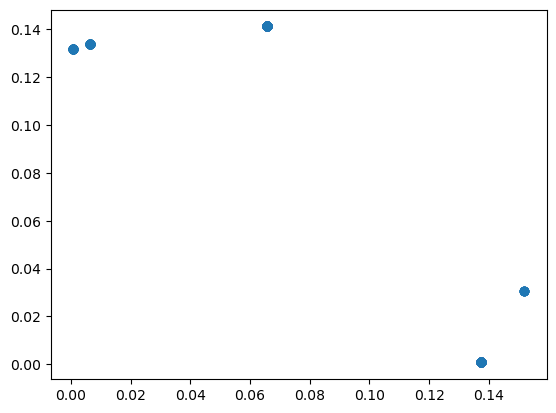

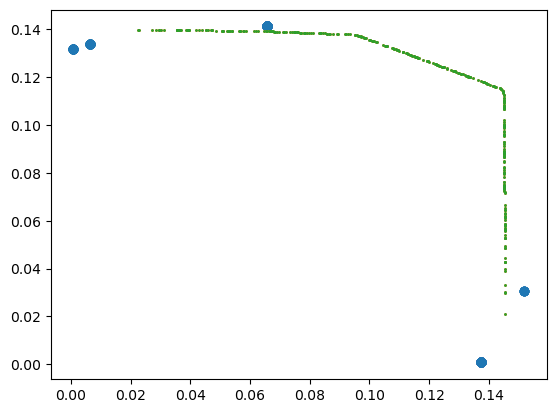

In [254]:

plt.scatter(cal_smx_list[0][np.arange(cal_labels.shape[0]), cal_labels]/t*t_quant,
            cal_smx_list[1][np.arange(cal_labels.shape[0]), cal_labels]/t*t_quant, s=1)

plt.scatter(env_list[5][0][0],
            env_list[5][0][1], s=1)

In [363]:
score_example_ = [np.random.rand(1,100000), np.random.rand(1,100000)]

In [364]:
prediction_sets_list = []
val_s_u_list = []

for j, th in enumerate(np.linspace(0,np.pi/2,n_th)):

    val_s_u, val_s_u_orth = project_u_mv(score_example_, U[j,:])
        
    prediction_sets = val_s_u <= q_array[j] * t_quant
        
    prediction_sets_list.append(prediction_sets)
        
prediction_sets_ = np.prod(prediction_sets_list,0) == 1
prediction_sets_

array([[False, False, False, ..., False, False, False]])

(0.0, 0.2)

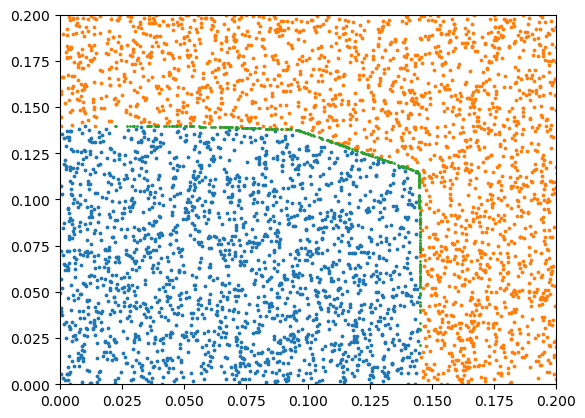

In [370]:
plt.scatter(score_example_[0][prediction_sets_],
            score_example_[1][prediction_sets_], s=3)

plt.scatter(score_example_[0][~prediction_sets_],
            score_example_[1][~prediction_sets_], s=3)

plt.scatter(env_list[5][0][0],
            env_list[5][0][1], s=1)

plt.xlim(0,.2)
plt.ylim(0,.2)

In [258]:
prediction_sets_list = []
val_s_u_list = []
for j in range(400):
    val_s_u = project_u_mv(score_example, U[j,:])[0]# <= q_array[j]*t_quant 
    val_s_u_list.append(val_s_u)
    prediction_sets = val_s_u <= q_array[j] * t_quant
    prediction_sets_list.append(prediction_sets)  
    

In [259]:
prediction_sets_ = np.prod(prediction_sets_list,0) == 1
prediction_sets_

array([[False, False, False, False, False, False]])

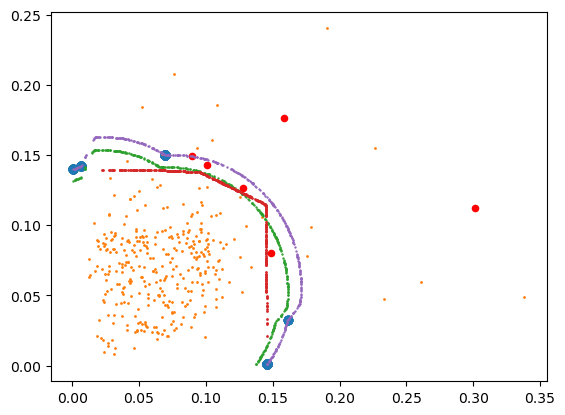

In [360]:
U_t = U[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(cal_labels.shape[0]),cal_labels]/q for th, q in enumerate(q_array)], 0),:]
plt.scatter(t_quant*U_t[:,0]*q_array[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(cal_labels.shape[0]),cal_labels]/q for th, q in enumerate(q_array)], 0)],
            t_quant*U_t[:,1]*q_array[np.argmax([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(cal_labels.shape[0]),cal_labels]/q for th, q in enumerate(q_array)], 0)])


plt.scatter(score_example[0],
            score_example[1], s=20, c='r')

plt.scatter(cal_smx_list[0][np.arange(cal_labels.shape[0]), cal_labels],
            cal_smx_list[1][np.arange(cal_labels.shape[0]), cal_labels], s=1)

plt.scatter(env_quant[:,0],
            env_quant[:,1], s=.5)

plt.scatter(env_list[5][0][0],
            env_list[5][0][1], s=1)

plt.scatter(t_quant*env_quant[:,0],
            t_quant*env_quant[:,1], s=.5)

In [108]:
n-np.prod(cov_list,0).sum()

4

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []


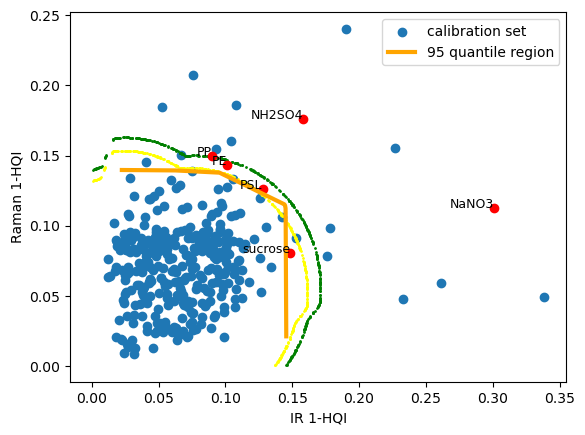

100%|█████████████████████████████████████████████| 1/1 [00:02<00:00,  2.12s/it]


In [221]:
ps_list, env_list, cal_smx_arr, quant_smx_list, quant_labels, cal_smx_list, cal_labels, q_array, U_quant_env, U = envelop_aux(score_list, label_ir, score_example,
#alphas=[.20, .10, 0.05, 0.02],
alphas=[.05],
N_sim=1, 
quant_prop=.2, 
cal_prop=0.8, 
seed_init=1)

In [46]:
20/(20+65), 65/(20+65)

(0.23529411764705882, 0.7647058823529411)

In [246]:
q_array = np.random.rand(400)*.1+.8

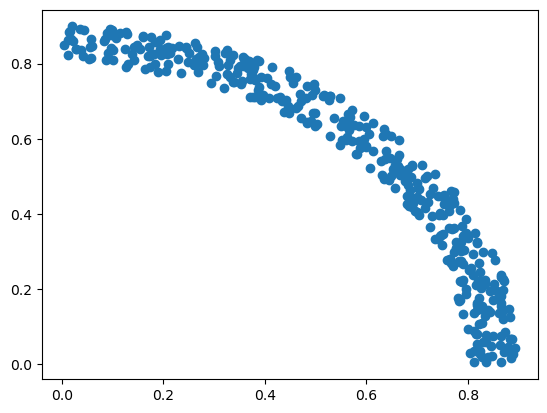

In [247]:
U = U_list[0]
U_quant_env = np.array([U[th] * q_array[th] for th in range(400)])
plt.scatter(U_quant_env[:,0],
         U_quant_env[:,1])

In [224]:
score_example[0].shape, np.array([[1]]).shape
#[np.array([[1]]), np.array([[1]])]


((1, 6), (1, 1))

In [227]:
u[0]

0.975224023736123

In [228]:
project_u_mv([np.array([[u[0]]]), np.array([[u[1]]])], 
             u)

(array([[1.]]), None)

In [36]:
label_table.iloc[0,1]

'NH2SO4'

In [74]:
ids_example = [130, 136, 217]

In [41]:
pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[281:282,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
281,-0.312222,-0.611566,-0.588891,-0.262753,-0.301178,-0.430421,-0.387344,-0.256565,-0.113283,-0.054495,...,-0.612874,-0.278379,0,0,LDPE,LDPE,NaN,PE,138,no_background


In [75]:
pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[277:278,:]


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
277,-0.349508,-0.352375,-0.383202,-0.403374,-0.41037,-0.387632,-0.347845,-0.325567,-0.314919,-0.295091,...,-0.105002,-0.051497,0,0,LDPE,LOW,NaN,PE,130,no_background


In [64]:
IR_spectra_mix_std_rest.shape
pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True).query('id in @ids_example')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
138,-0.580840,-0.575939,-0.561041,-0.544883,-0.548383,-0.558500,-0.555964,-0.556645,-0.572358,-0.571250,...,-0.431521,-0.429762,0,0,PSL,MIX,PSL AND SN?,MIXTURE,217,no_background
172,-0.061813,-0.495358,0.555116,0.750589,0.169358,0.425192,-0.654958,-1.672618,-0.539975,0.142778,...,4.257040,1.043177,0,0,UNS,LOW,FLUORESCENCE,UNSORTED,136,background
330,-0.458293,-0.381986,-0.291597,-0.071482,0.102961,0.042253,-0.242010,-0.278758,-0.181451,-0.101000,...,-0.754732,-0.923426,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,136,no_background
333,-0.596220,-0.590548,-0.590095,-0.600481,-0.602661,-0.594409,-0.589836,-0.580672,-0.558146,-0.550383,...,1.858261,1.505509,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,217,no_background


In [60]:
IR_spectra_mix_rest.query('id == 136 or id == 217')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
125,-0.458293,-0.381986,-0.291597,-0.071482,0.102961,0.042253,-0.242010,-0.278758,-0.181451,-0.101000,...,-0.754732,-0.923426,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,136,no_background
128,-0.596220,-0.590548,-0.590095,-0.600481,-0.602661,-0.594409,-0.589836,-0.580672,-0.558146,-0.550383,...,1.858261,1.505509,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,217,no_background


In [211]:
#score_example = [score_list[0][281:282], score_list[1][281:282]] # id == 138

#score_example = [score_list[0][277:278], score_list[1][277:278]] # id == 130
#print(pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[277:278,:]['id'])

#score_example = [score_list_rest[0][330:331], score_list_rest[1][330:331]]
#print(pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True).iloc[330:331,:]['id'])

score_example = [score_list_rest[0][333:334], score_list_rest[1][333:334]]
print(pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True).iloc[333:334,:]['id'])


333    217
Name: id, dtype: int64


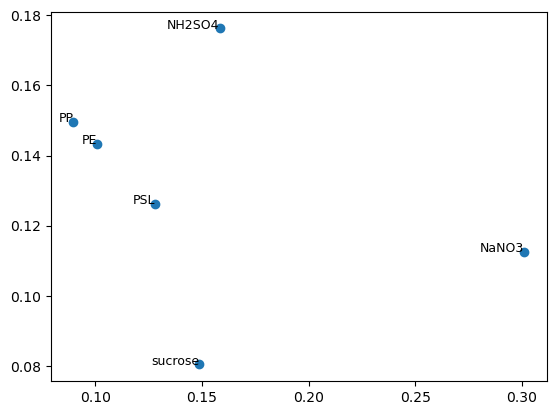

In [214]:
plt.scatter(score_example[0],
            score_example[1])

for i in range(6):
    plt.text(score_example[0][0, i], 
             score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')

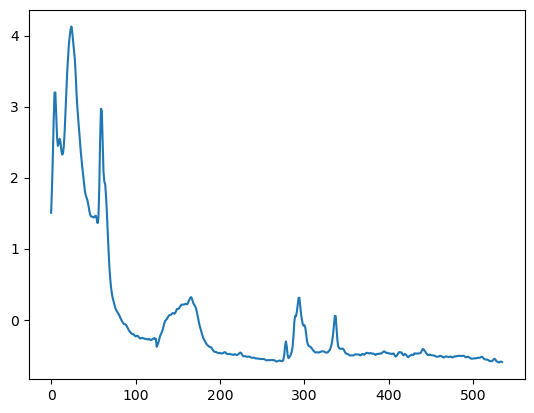

In [24]:
#_ = plt.plot(np.array(IR_spectra_mix.query('id == 130').iloc[0,:-8])[::-1].T)
_ = plt.plot(np.array(IR_spectra_mix_rest.query('id == 217').iloc[0,:-8])[::-1].T)

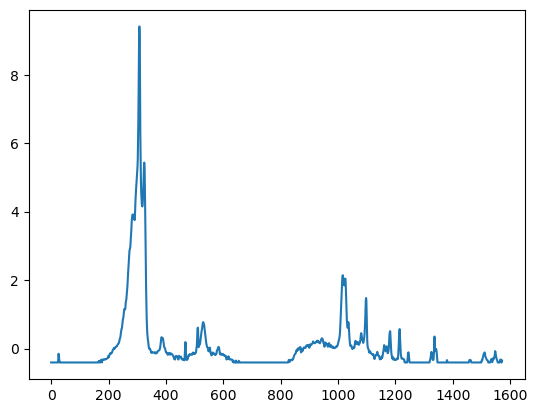

In [25]:
#_ = plt.plot(np.array(Raman_spectra_mix.query('id == 130').iloc[0,:-4])[::-1].T)
_ = plt.plot(np.array(Raman_spectra_mix_rest.query('id == 217').iloc[0,:-4])[::-1].T)

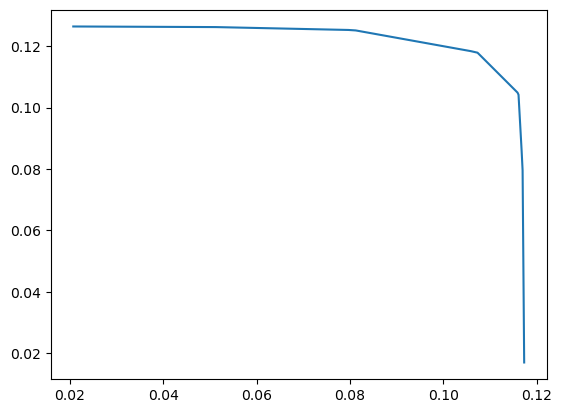

In [26]:
plt.scatter(cal_smx_arr[0,:],
            cal_smx_arr[1,:])

plt.scatter(score_example[0],
            score_example[1], color='r')
for i in range(6):
    plt.text(score_example[0][0, i], 
             score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right', c='black')


plt.plot(env_list[5][0][0],
         env_list[5][0][1], c='orange')

NameError: name 'cal_smx_arr' is not defined

In [27]:
cal_data = np.array([cal_smx_arr[0,:],
                     cal_smx_arr[1,:]]).T

NameError: name 'cal_smx_arr' is not defined

In [28]:
env_ = np.array([env_list[5][0][0],
                 env_list[5][0][1]]).T

NameError: name 'env_list' is not defined

In [85]:
U = gen_u(2, seed=0)[0]
U = U[np.argsort(U[:,0]),:]
U

array([[0.0058794 , 0.99998272],
       [0.01437189, 0.99989672],
       [0.0150222 , 0.99988716],
       [0.0163694 , 0.99986601],
       [0.01808518, 0.99983645],
       [0.02169913, 0.99976455],
       [0.02331122, 0.99972826],
       [0.02536954, 0.99967814],
       [0.03294296, 0.99945723],
       [0.03361086, 0.999435  ],
       [0.03979796, 0.99920775],
       [0.04484561, 0.99899393],
       [0.0481348 , 0.99884085],
       [0.05096208, 0.99870059],
       [0.06565336, 0.99784249],
       [0.06594432, 0.9978233 ],
       [0.06638507, 0.99779408],
       [0.06908206, 0.99761098],
       [0.06969556, 0.99756831],
       [0.09698848, 0.9952855 ],
       [0.09856616, 0.9951305 ],
       [0.09972576, 0.99501496],
       [0.10502653, 0.99446942],
       [0.10772431, 0.99418081],
       [0.10884307, 0.99405894],
       [0.10906743, 0.99403435],
       [0.10947159, 0.99398992],
       [0.11489579, 0.99337755],
       [0.1187343 , 0.99292606],
       [0.12269986, 0.99244382],
       [0.

In [96]:
[U[th] @ for th in range(U.shape[0])]

[array([0.0058794 , 0.99998272]),
 array([0.01437189, 0.99989672]),
 array([0.0150222 , 0.99988716]),
 array([0.0163694 , 0.99986601]),
 array([0.01808518, 0.99983645]),
 array([0.02169913, 0.99976455]),
 array([0.02331122, 0.99972826]),
 array([0.02536954, 0.99967814]),
 array([0.03294296, 0.99945723]),
 array([0.03361086, 0.999435  ]),
 array([0.03979796, 0.99920775]),
 array([0.04484561, 0.99899393]),
 array([0.0481348 , 0.99884085]),
 array([0.05096208, 0.99870059]),
 array([0.06565336, 0.99784249]),
 array([0.06594432, 0.9978233 ]),
 array([0.06638507, 0.99779408]),
 array([0.06908206, 0.99761098]),
 array([0.06969556, 0.99756831]),
 array([0.09698848, 0.9952855 ]),
 array([0.09856616, 0.9951305 ]),
 array([0.09972576, 0.99501496]),
 array([0.10502653, 0.99446942]),
 array([0.10772431, 0.99418081]),
 array([0.10884307, 0.99405894]),
 array([0.10906743, 0.99403435]),
 array([0.10947159, 0.99398992]),
 array([0.11489579, 0.99337755]),
 array([0.1187343 , 0.99292606]),
 array([0.1226

In [94]:
[U[np.argmax(U @ env_[i] / np.linalg.norm(env_[i]))] for i in range(cal_data.shape[0])]

[array([0.16100078, 0.98695428]),
 array([0.17998701, 0.98366899]),
 array([0.17998701, 0.98366899]),
 array([0.1984921 , 0.98010249]),
 array([0.1984921 , 0.98010249]),
 array([0.19968597, 0.97985995]),
 array([0.20830844, 0.97806318]),
 array([0.20856694, 0.97800809]),
 array([0.21937311, 0.97564104]),
 array([0.24380083, 0.96982532]),
 array([0.24380083, 0.96982532]),
 array([0.24380083, 0.96982532]),
 array([0.24380083, 0.96982532]),
 array([0.24932841, 0.96841899]),
 array([0.24991975, 0.96826655]),
 array([0.25386641, 0.96723929]),
 array([0.25386641, 0.96723929]),
 array([0.25386641, 0.96723929]),
 array([0.25546962, 0.96681708]),
 array([0.25546962, 0.96681708]),
 array([0.26285438, 0.96483552]),
 array([0.27175629, 0.9623661 ]),
 array([0.27175629, 0.9623661 ]),
 array([0.27175629, 0.9623661 ]),
 array([0.27175629, 0.9623661 ]),
 array([0.29008388, 0.95700122]),
 array([0.29446665, 0.95566175]),
 array([0.30106252, 0.9536044 ]),
 array([0.30893052, 0.95108461]),
 array([0.3132

In [93]:
[U[np.argmax(U @ cal_data[i] / np.linalg.norm(cal_data[i]))] for i in range(cal_data.shape[0])]

[array([0.70124525, 0.71292012]),
 array([0.52661413, 0.85010444]),
 array([0.93303779, 0.35977839]),
 array([0.88601999, 0.46364704]),
 array([0.67813917, 0.73493352]),
 array([0.90845839, 0.4179753 ]),
 array([0.85905092, 0.51189014]),
 array([0.74361369, 0.66860951]),
 array([0.61890755, 0.78546384]),
 array([0.5680302 , 0.82300771]),
 array([0.25386641, 0.96723929]),
 array([0.78124583, 0.62422348]),
 array([0.86453539, 0.50257195]),
 array([0.48418089, 0.87496792]),
 array([0.70381311, 0.71038518]),
 array([0.9542628 , 0.29896909]),
 array([0.58451587, 0.81138228]),
 array([0.49852174, 0.8668772 ]),
 array([0.43221611, 0.90177006]),
 array([0.89253987, 0.4509685 ]),
 array([0.76229584, 0.64722875]),
 array([0.68490931, 0.72862832]),
 array([0.19968597, 0.97985995]),
 array([0.89970788, 0.43649252]),
 array([0.89253987, 0.4509685 ]),
 array([0.61890755, 0.78546384]),
 array([0.53286463, 0.8462005 ]),
 array([0.17998701, 0.98366899]),
 array([0.25546962, 0.96681708]),
 array([0.9468

In [31]:
label_table

,label,polymer
0,0,NH2SO4
1,1,NaNO3
2,2,PE
3,3,PP
4,4,PSL
5,5,sucrose


In [198]:
score_example[0][0,-1], score_example[1][0,-1]

(0.14866326709813027, 0.08042207005494428)

In [210]:
score_list[0].shape, label_ir.shape

((530, 6), (530,))

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PE', 'PP']
Raman ['NaNO3', 'PSL', 'sucrose']


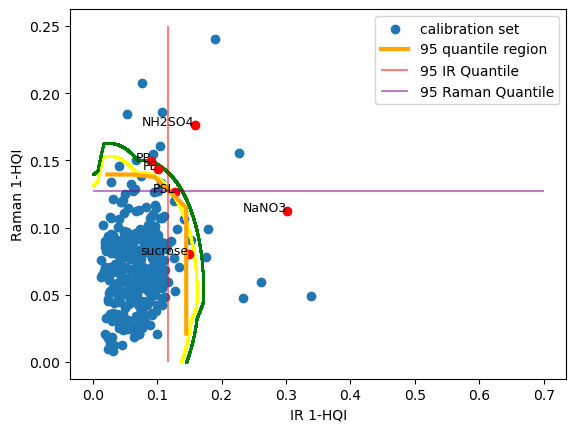

100%|█████████████████████████████████████████████| 1/1 [00:28<00:00, 28.53s/it]


In [213]:
ps_list, ps_ir_list, ps_raman_list, env_list, cal_smx_arr, q_ir_list, q_raman_list = envelop(score_list, label_ir, score_example,
#alphas=[.20, .10, 0.05, 0.02],
alphas=[.05],
N_sim=1, 
quant_prop=.2, 
cal_prop=0.8, 
seed_init=1)

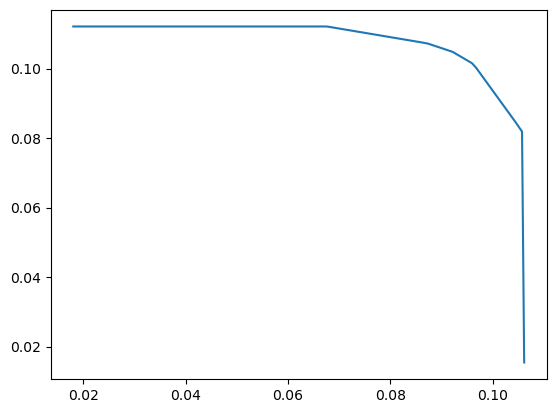

In [85]:
_ = plt.plot(env_list[20][0][0],
env_list[20][0][1])

In [162]:
ps_list, ps_ir_list, ps_raman_list, q_ir_list, q_raman_list

(defaultdict(list, {20: [[]], 10: [[]], 5: [['sucrose']]}),
 defaultdict(list, {20: [['PP']], 10: [['PE', 'PP']], 5: [['PE', 'PP']]}),
 defaultdict(list,
             {20: [['sucrose']],
              10: [['sucrose']],
              5: [['NaNO3', 'sucrose']]}),
 defaultdict(list,
             {20: [0.0941985968436867],
              10: [0.10738025078634494],
              5: [0.12578791882957097]}),
 defaultdict(list,
             {20: [0.09487330234190128],
              10: [0.10850422652393032],
              5: [0.1198462543878891]}))

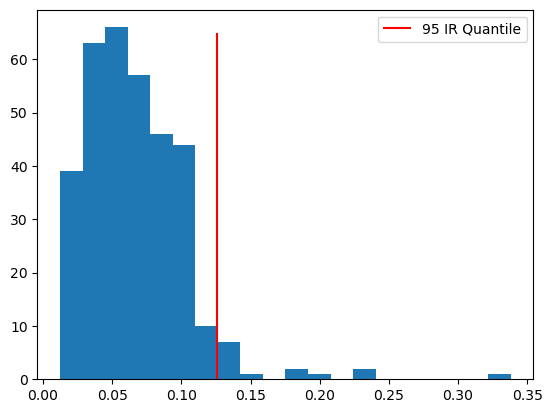

In [143]:
h_ir = plt.hist(cal_smx_arr[0],bins=20, density=False)
_ = plt.vlines(x= q_ir_list[5],
                ymin=0,
                ymax=65,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()

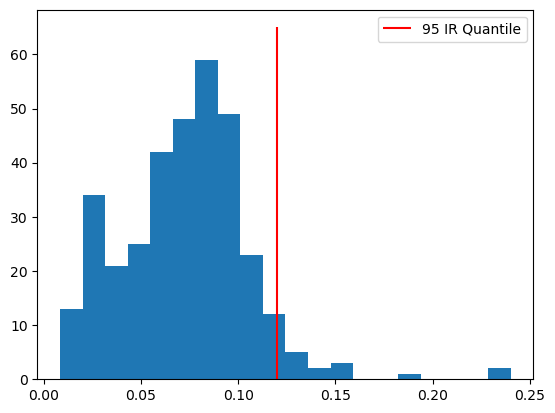

In [144]:
h_raman = plt.hist(cal_smx_arr[1],bins=20, density=False)
_ = plt.vlines(x= q_raman_list[5],
                ymin=0,
                ymax=65,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()

In [104]:
h_ir[1]

array([0.0122862 , 0.02858032, 0.04487443, 0.06116855, 0.07746266,
       0.09375678, 0.11005089, 0.12634501, 0.14263912, 0.15893324,
       0.17522735, 0.19152147, 0.20781558, 0.2241097 , 0.24040381,
       0.25669793, 0.27299204, 0.28928616, 0.30558028, 0.32187439,
       0.33816851])

In [105]:
pd.DataFrame({'1-HQI':h_ir[1][:-1], 
              '# IR':h_ir[0],
              '# Raman':h_raman[0]
              })#.to_csv('results/hist_data_fig_2a.csv')

,1-HQI,# IR,# Raman
0,0.012286,39.0,13.0
1,0.028580,63.0,34.0
2,0.044874,66.0,21.0
3,0.061169,57.0,25.0
4,0.077463,46.0,42.0
5,0.093757,44.0,48.0
6,0.110051,10.0,59.0
7,0.126345,7.0,49.0
8,0.142639,1.0,23.0
9,0.158933,0.0,12.0


In [109]:
cal_smx_arr[0].shape

(339,)

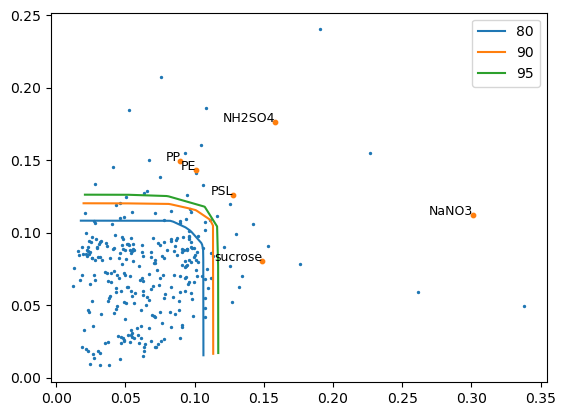

In [192]:
env_data_80 = pd.DataFrame(np.array(env_list[20][0]).T)
env_data_90 = pd.DataFrame(np.array(env_list[10][0]).T)
env_data_95 = pd.DataFrame(np.array(env_list[5][0]).T)

env_data_80.columns = ['x - 80','y - 80']
env_data_90.columns = ['x - 90','y - 90']
env_data_95.columns = ['x - 95','y - 95']

plt.scatter(cal_smx_arr[0],
            cal_smx_arr[1], s=2)

plt.scatter(score_example[0],
            score_example[1], s=10)

for i in range(6):
    plt.text(score_example[0][0, i], 
             score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')
    
    
_ = plt.plot(env_data_80['x - 80'],
             env_data_80['y - 80'], label='80')

_ = plt.plot(env_data_90['x - 90'],
             env_data_90['y - 90'], label='90')

_ = plt.plot(env_data_95['x - 95'],
             env_data_95['y - 95'], label='95')

_ = plt.legend()

In [237]:
cal_data = pd.DataFrame(cal_smx_list.T)
cal_data.columns = ['IR', 'Raman']
cal_data.to_csv('results/calibration_data_fig_1.csv')
cal_data

,IR,Raman
0,0.033002,0.036592
1,0.057135,0.058291
2,0.024109,0.009370
3,0.043478,0.017015
4,0.100308,0.094801
...,...,...
334,0.037226,0.067002
335,0.082613,0.093965
336,0.069389,0.062526
337,0.042864,0.058994


In [238]:
env_data = pd.concat([env_data_80, env_data_90, env_data_95],axis=1)
env_data.to_csv('results/envelopes_data_fig_1.csv')
env_data

,x - 80,y - 80,x - 90,y - 90,x - 95,y - 95
0,0.018055,0.112113,0.020330,0.126241,0.021362,0.132645
1,0.020313,0.112113,0.022873,0.126241,0.024033,0.132645
2,0.020588,0.112113,0.023182,0.126241,0.024358,0.132645
3,0.021795,0.112113,0.024541,0.126241,0.025786,0.132645
4,0.021806,0.112113,0.024554,0.126241,0.025800,0.132645
...,...,...,...,...,...,...
334,0.106075,0.029165,0.112288,0.030874,0.153071,0.042087
335,0.106100,0.025080,0.112315,0.026549,0.153108,0.036191
336,0.106112,0.023213,0.112327,0.024573,0.153125,0.033498
337,0.106122,0.021585,0.112338,0.022849,0.153140,0.031148


In [164]:
hqi_ex = pd.DataFrame({'polymer':label_table['polymer'],
              '(1-HQI) IR':score_example[0][0], 
              '(1-HQI) Raman':score_example[1][0]})
hqi_ex.to_csv('results/hqi_example_data_fig_1_id_217.csv')
hqi_ex

,polymer,(1-HQI) IR,(1-HQI) Raman
0,NH2SO4,0.158350,0.176216
1,NaNO3,0.301043,0.112436
2,PE,0.100956,0.143274
3,PP,0.089685,0.149578
4,PSL,0.127920,0.126260
5,sucrose,0.148663,0.080422


In [165]:
pred_sets_ex = (pd.DataFrame(ps_list).T).reset_index()
pred_sets_ex['index'] = 100 - pred_sets_ex['index']
pred_sets_ex.columns = ['confidence', 'prediction set']
pred_sets_ex.to_csv('results/pred_sets_fig_1_id_217.csv')
pred_sets_ex

,confidence,prediction set
0,80,[]
1,90,[]
2,95,[sucrose]


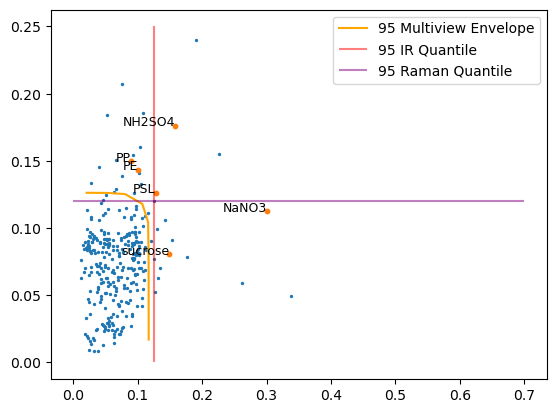

In [193]:
env_data_95 = pd.DataFrame(np.array(env_list[5][0]).T)
env_data_95.columns = ['x - 95','y - 95']

plt.scatter(cal_smx_arr[0],
            cal_smx_arr[1], s=2)

plt.scatter(score_example[0],
            score_example[1], s=10)

for i in range(6):
    plt.text(score_example[0][0, i], 
             score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')
    
    
_ = plt.plot(env_data_95['x - 95'],
             env_data_95['y - 95'], color='orange', label='95 Multiview Envelope')

_ = plt.vlines(x= q_ir,
                ymin=0,
                ymax=.25,
                colors='r',
                alpha=.5,
                linestyles='solid',
                label='95 IR Quantile')

_ = plt.hlines(y= q_raman,
                xmin=0,
                xmax=.7,
                colors='purple',
                alpha=.5,
                linestyles='solid',
                label='95 Raman Quantile')

_ = plt.legend()

In [167]:
q_raman = q_raman_list[5][0]

In [168]:
q_ir = q_ir_list[5][0]

In [169]:
pred_sets_95_ex = pd.DataFrame({'IR':ps_ir_list[5],
              'Raman':ps_raman_list[5],
              'MVCP':ps_list[5]})
pred_sets_95_ex.to_csv('results/pred_sets_95_fig_2a_id_217.csv')
pred_sets_95_ex

,IR,Raman,MVCP
0,"[PE, PP]","[NaNO3, sucrose]",[sucrose]


In [120]:
quantile_95 = pd.DataFrame({'95 IR Quantile':[q_ir],
              '95 Raman Quantile':[q_raman]})
#quantile_95.to_csv('results/quantile_95_data_fig_2a.csv')
quantile_95

,95 IR Quantile,95 Raman Quantile
0,0.125788,0.119846


In [125]:
alpha = .1
beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels)
#U = np.array([u/np.linalg.norm(u) for u in U])
n = rest_smx_list[0].shape[0]
t = np.max([project_u_mv(rest_smx_list, U[th,:])[0][np.arange(n),rest_labels]/q for th, q in enumerate(q_array)], 0)


cal_x = smx_all_IR[np.arange(label_ir.shape[0]),label_ir]
cal_y = smx_all_Raman[np.arange(label_ir.shape[0]),label_ir]

#plt.scatter(cal_x[cal_x<.2],
#            cal_y[cal_x<.2], 
#            label='calibration set')

plt.scatter(quant_smx_list[0][np.arange(quant_labels.shape[0]),quant_labels],
            quant_smx_list[1][np.arange(quant_labels.shape[0]),quant_labels], 
            label='calibration set')

#plt.scatter(smx_all_IR_rest.min(1),
#            smx_all_Raman_rest.min(1))

#plt.scatter(U[:,0],
#            U[:,1])

#plt.scatter(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t,
#            rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t, 
#            label='quantile region')

idx_quant_reg = np.argsort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_x = np.sort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_y = (rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t)[idx_quant_reg]

plt.plot(quant_reg_x,
         quant_reg_y, 
         label='quantile region',
         c='orange',
         linewidth=3.0
     )

plt.xlabel("IR 1-HQI")
plt.ylabel("Raman 1-HQI")
plt.xlim(0.0,.16)
plt.ylim(0.0,.16)

plt.legend()

NameError: name 'quant_smx_list' is not defined

# C